# ECON 354: Interpretable Machine Learning for Baseline Borrower Default Risk ($PD_{\text{base}}$) & Ontario Macroeconomic Sensitivity
## Phase 1: Real-Data Pipeline, Leakage-Free Preprocessing & Dimensionality Reduction

**Authors:** Alex Babiak, Marco Puiatti  
**Scope:** Ontario, Canada  

### Research Question
> *"How can machine learning be used to estimate individual borrower baseline default risk ($PD_{\text{base}}$), and how sensitive is that baseline risk distribution to Ontario macroeconomic shocks in unemployment and inflation?"*

---

### Datasets Used & Justifications (100% Real Data — Zero Synthetic Data)
1. **Individual Borrower Microdata (`credit_risk_dataset.csv` — 32,581 records, 12 variables):**
   - **Source:** Programmatically fetched via `urllib.request` from `https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/credit_risk_dataset.csv`.
   - **Why it is used:** Institutional Canadian mortgage loan-level files (e.g., CMHC or Schedule I banks) are restricted under PIPEDA privacy regulations and proprietary trade secrecy. This 32,581-record empirical credit dataset serves as a transparent micro-level proxy capturing authentic borrower balance-sheet relationships (`person_income`, `loan_amnt`, `loan_percent_income`), credit and employment stability (`cb_person_cred_hist_length`, `person_emp_length`), loan interest rates and credit risk grades (`loan_int_rate`, `loan_grade`), and observed binary default outcomes (`loan_status`, ~21.82% default incidence). Using real microdata preserves genuine right-skewed financial tails, missingness patterns, and feature multicollinearity.

2. **Ontario Macroeconomic Time-Series (Statistics Canada Web Data Service API):**
   - **Source:** Programmatically queried via POST request to StatCan's public WDS API (`https://www150.statcan.gc.ca/t1/wds/rest/getDataFromVectorsAndLatestNPeriods`) for Ontario Monthly Unemployment Rate (`v2062815`, Table 14-10-0287-01) and Ontario All-Items CPI (`v41690973`, Table 18-10-0004-01), computing 12-month Year-over-Year inflation (`Ontario_CPI_YoY`).
   - **Why it is used:** Cross-sectional borrower data is "point-in-time" and blind to business-cycle fluctuations. Pairing individual baseline default probabilities ($PD_{\text{base}}$) with official Ontario labor-market and inflation series allows us to test how regional macroeconomic shocks perturb baseline borrower risk distributions (used strictly as environmental stress parameters on $PD_{\text{base}}$).

---

### Explicit Model Outcomes
1. **Primary Binary Outcome ($y_i \in \{0, 1\}$):** Observed borrower default indicator (`loan_status`, where $1$ = default and $0$ = performing; 21.82% population default incidence).
2. **Primary Continuous Outcome ($PD_{\text{base}, i} \in [0, 1]$):** Calibrated individual baseline Probability of Default generated via Platt sigmoid scaling on the RBF-SVM decision function $f(\mathbf{x}_i)$ (benchmarked against Logistic Regression).
3. **Secondary Stress Outcome ($PD_{\text{stressed}, i} \in [0, 1]$):** Macro-adjusted borrower default probability resulting from shifting baseline log-odds by Ontario unemployment and CPI inflation shocks.
4. **Out-of-Sample Evaluation Outcomes (Test Set, $N = 4,888$):** Discriminatory power (ROC-AUC, F1-Score, Accuracy) and probability calibration (Brier Score, Log Loss, Mean Predicted PD vs. Actual Default Rate).

---

### Explicit Model Parameters
1. **Raw Applicant Inputs ($\mathbf{x}_{\text{raw}}$):** 11 borrower predictors (5 collinear financial variables, 2 continuous demographic/rate controls, and 4 categorical indicators expanded via one-hot encoding into 23 features, then compressed to 20 post-PCA features).
2. **Preprocessing Parameters:** Training-set medians ($m_{\text{train}}$) for missing value imputation (`person_emp_length`, `loan_int_rate`), training-set Tukey $1.5 \times \text{IQR}$ fences ($[Q_1 - 1.5\text{IQR},\; Q_3 + 1.5\text{IQR}]$) for outlier capping (`person_income`, `loan_amnt`), and training-set `StandardScaler` moments ($\boldsymbol{\mu}_{\text{train}}, \boldsymbol{\sigma}_{\text{train}}$).
3. **Dimensionality Reduction Parameters:** PCA eigenvector projection matrix $\mathbf{W} \in \mathbb{R}^{5 \times 3}$ capturing 81.90% of continuous financial variance across three orthogonal risk factors (`PC1_Financial_Scale`, `PC2_Tenure_Stability`, `PC3_Leverage_Burden`).
4. **Classifier & Macro Sensitivity Parameters:** SVM soft-margin regularization ($C$), RBF kernel bandwidth ($\gamma$), Platt scaling parameters ($A, B$), and Ontario macro elasticities ($\beta_1, \beta_2$).

### 1. Environment Setup & Real-Data Ingestion (Borrower Microdata + StatCan WDS API)
We consolidate all Phase 1 library imports and global reproducibility seeds, then ingest the two 100% real datasets:
1. **Borrower Microdata (`credit_risk_dataset.csv`):** 32,581 empirical borrower records fetched via `urllib.request`, serving as a transparent micro-level proxy given PIPEDA and proprietary restrictions on institutional Canadian mortgage files.
2. **Ontario Macroeconomic Time-Series:** Programmatically queried via Statistics Canada's public WDS API for Ontario's monthly Unemployment Rate (`v2062815`, Table 14-10-0287-01) and All-Items CPI (`v41690973`, Table 18-10-0004-01), computing 12-month YoY inflation (`Ontario_CPI_YoY`) and persisting `ontario_macro_series.parquet` for Phase 2 macro-sensitivity testing of $PD_{\text{base}}$.

In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & REAL-DATA INGESTION (100% REAL DATA)
# ==============================================================================
import json
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Configure publication-grade plotting aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------------------------
# STEP 1: INGEST REAL BORROWER MICRODATA (32,581 RECORDS, 12 VARIABLES)
# Proxy for PIPEDA-restricted Canadian institutional mortgage files
# ------------------------------------------------------------------------------
print("--- STEP 1: INGESTING REAL MICRO CREDIT RISK DATASET ---")
micro_url = "https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/credit_risk_dataset.csv"
micro_dest = "credit_risk_dataset.csv"

try:
    urllib.request.urlretrieve(micro_url, micro_dest)
    print("Credit risk dataset downloaded successfully.")
except Exception as e:
    raise RuntimeError(f"Critical failure downloading micro credit data: {e}") from e

df_raw = pd.read_csv(micro_dest)
assert df_raw.shape == (32581, 12), f"Unexpected microdata shape: {df_raw.shape}"

print(f"Raw Microdata Shape: {df_raw.shape}")
print("\n--- Microdata Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Microdata Information ---")
df_raw.info()

# ------------------------------------------------------------------------------
# STEP 2: PROGRAMMATIC STATISTICS CANADA WDS API EXTRACTION (ONTARIO MACRO)
# Environmental stress series for Phase 2 macro-sensitivity testing of PD_base
# ------------------------------------------------------------------------------
print("\n--- STEP 2: PROGRAMMATIC STATISTICS CANADA WDS API FETCH (100% REAL DATA) ---")
statcan_url = "https://www150.statcan.gc.ca/t1/wds/rest/getDataFromVectorsAndLatestNPeriods"
headers = {"Content-Type": "application/json"}

# Vector 2062815: Ontario Monthly Unemployment Rate (Table 14-10-0287-01)
# Vector 41690973: Ontario All-Items Consumer Price Index (Table 18-10-0004-01)
payload = [
    {"vectorId": 2062815, "latestN": 120},
    {"vectorId": 41690973, "latestN": 120},
]

try:
    response = requests.post(statcan_url, json=payload, headers=headers, timeout=30)
    response.raise_for_status()
    api_data = response.json()

    series_list = []
    for series in api_data:
        # Parse nested StatCan JSON hierarchy: series["object"]["vectorId"]
        obj = series["object"]
        vec_id = int(obj["vectorId"])
        points = obj["vectorDataPoint"]
        for pt in points:
            if pt.get("value") is not None:
                series_list.append({
                    "vectorId": vec_id,
                    "refPer": pt["refPer"],
                    "value": float(pt["value"]),
                })

    df_macro_raw = pd.DataFrame(series_list)

    # Pivot wide on reference period (refPer) and clean axis metadata
    df_macro = df_macro_raw.pivot(
        index="refPer", columns="vectorId", values="value"
    ).reset_index()
    df_macro.columns.name = None
    df_macro.rename(
        columns={
            2062815: "Ontario_Unemployment_Rate",
            41690973: "Ontario_CPI",
        },
        inplace=True,
    )

    df_macro["Date"] = pd.to_datetime(df_macro["refPer"], format="%Y-%m-%d")
    df_macro = df_macro.sort_values("Date").reset_index(drop=True)

    # Drop any unaligned trailing/leading release months prior to YoY differencing
    df_macro.dropna(subset=["Ontario_Unemployment_Rate", "Ontario_CPI"], inplace=True)
    df_macro.reset_index(drop=True, inplace=True)

    # Compute Year-over-Year (YoY) CPI inflation without deprecated implicit padding
    df_macro["Ontario_CPI_YoY"] = (
        df_macro["Ontario_CPI"].pct_change(periods=12, fill_method=None) * 100.0
    )

    # Drop initial 12 differencing NaNs and verify zero remaining nulls
    df_macro.dropna(subset=["Ontario_CPI_YoY"], inplace=True)
    df_macro.reset_index(drop=True, inplace=True)
    assert df_macro.isnull().sum().sum() == 0, "NaNs detected in df_macro!"

    # Serialize clean Ontario macro time-series for Phase 2 PD_base sensitivity testing
    df_macro.to_parquet("ontario_macro_series.parquet", index=False)

    print(
        "\nStatCan Real Macro Data parsed and serialized to "
        "'ontario_macro_series.parquet' for Phase 2 PD_base macro-sensitivity testing."
    )
    print(f"Macrodata Shape: {df_macro.shape}")
    display(df_macro.head())
    display(df_macro.tail())
except Exception as e:
    print("StatCan Request failed. Raw Exception detail:", e)
    if "response" in locals() and hasattr(response, "text"):
        print("Server Response Text:", response.text)
    raise RuntimeError(
        "Macro data fetch failed. Terminating to preserve 100% Real Data constraint."
    ) from e

--- STEP 1: INGESTING REAL MICRO CREDIT RISK DATASET ---


Credit risk dataset downloaded successfully.
Raw Microdata Shape: (32581, 12)

--- Microdata Missing Values ---
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

--- Microdata Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length        


StatCan Real Macro Data parsed and serialized to 'ontario_macro_series.parquet' for Phase 2 PD_base macro-sensitivity testing.
Macrodata Shape: (107, 5)


,refPer,Ontario_Unemployment_Rate,Ontario_CPI,Date,Ontario_CPI_YoY
0,2017-11-01,6.2,131.3,2017-11-01,2.099533
1,2017-12-01,6.0,130.8,2017-12-01,1.869159
2,2018-01-01,5.9,131.7,2018-01-01,1.698842
3,2018-02-01,6.0,132.5,2018-02-01,2.158828
4,2018-03-01,5.8,132.9,2018-03-01,2.309469


,refPer,Ontario_Unemployment_Rate,Ontario_CPI,Date,Ontario_CPI_YoY
102,2026-05-01,6.6,169.6,2026-05-01,3.225806
103,2026-06-01,6.5,169.0,2026-06-01,2.798054
104,2026-07-01,6.4,169.9,2026-07-01,3.032141
105,2026-08-01,6.4,169.8,2026-08-01,3.033981
106,2026-09-01,6.5,170.0,2026-09-01,3.092784


### 2. Leakage-Free Exploratory Data Analysis & Preprocessing
We perform out-of-sample disciplined preprocessing on the real borrower microdata:
1. **Median Imputation:** Missing values in `person_emp_length` and `loan_int_rate` are imputed using medians fitted strictly on the 70% stratified training index (`train_idx`).
2. **Tukey's $1.5 \times \text{IQR}$ Outlier Capping:** Monetary variables (`person_income`, `loan_amnt`) are Winsorized at $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$ using training-split quartiles. Note that `loan_amnt` is capped and retained strictly for leverage ratio calculation and PCA compression (not as an unscaled exposure input).
3. **Feature Engineering & One-Hot Encoding:** We recompute `loan_percent_income = loan_amnt / person_income`, one-hot encode categorical variables (`drop_first=True`, `dtype=int`), and render the Pearson correlation heatmap across the 5 continuous financial features.

--- STEP 1: IMPUTING MISSING MICRODATA ---
Imputed person_emp_length with median: 4.0 years
Imputed loan_int_rate with median:     10.99%
Remaining nulls in dataset:            0

--- STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING ---
person_income   | IQR Bounds: [$ -23140.62, $ 141300.38] | Capped Below:    0 | Capped Above: 1465
loan_amnt       | IQR Bounds: [$  -5875.00, $  23125.00] | Capped Below:    0 | Capped Above: 1687

--- STEP 3: FEATURE ENGINEERING ---
Recalculated loan_percent_income summary: min=0.0071, max=0.8300, mean=0.1700

--- STEP 4: CATEGORICAL ONE-HOT ENCODING ---
Post-encoding dataset shape: (32581, 23)

--- STEP 5: MULTICOLLINEARITY CORRELATION HEATMAP ---


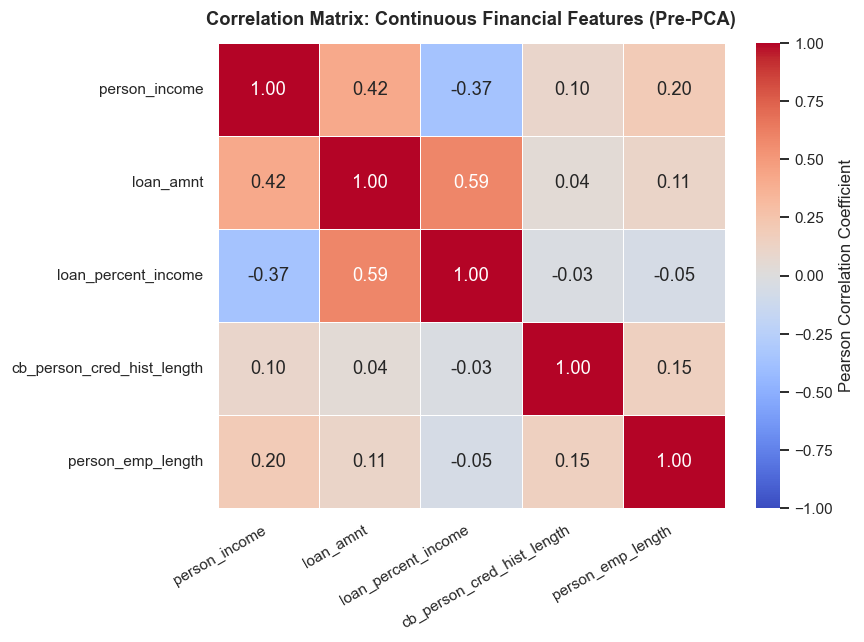

In [2]:
# ==============================================================================
# CELL 2: LEAKAGE-FREE EXPLORATORY DATA ANALYSIS & PREPROCESSING
# ==============================================================================
df_clean = df_raw.copy()

# Identify the exact 70% stratified training index so median and IQR statistics
# are estimated strictly on training observations (zero pre-split leakage).
train_idx, _ = train_test_split(
    df_clean.index,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=df_clean["loan_status"],
)

# ------------------------------------------------------------------------------
# STEP 1: IMPUTING MISSING MICRODATA (TRAINING-ONLY ROBUST MEDIANS)
# ------------------------------------------------------------------------------
print("--- STEP 1: IMPUTING MISSING MICRODATA ---")
person_emp_length_med = df_clean.loc[train_idx, "person_emp_length"].median()
loan_int_rate_med = df_clean.loc[train_idx, "loan_int_rate"].median()

df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(
    person_emp_length_med
)
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(loan_int_rate_med)

print(f"Imputed person_emp_length with median: {person_emp_length_med:.1f} years")
print(f"Imputed loan_int_rate with median:     {loan_int_rate_med:.2f}%")
print(f"Remaining nulls in dataset:            {df_clean.isnull().sum().sum()}")

# ------------------------------------------------------------------------------
# STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING (TRAINING-ONLY FENCES)
# loan_amnt is capped and retained strictly for leverage ratio calculation and PCA
# ------------------------------------------------------------------------------
print("\n--- STEP 2: TUKEY 1.5x IQR OUTLIER CAPPING ---")
for col in ["person_income", "loan_amnt"]:
    q25 = df_clean.loc[train_idx, col].quantile(0.25)
    q75 = df_clean.loc[train_idx, col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr

    num_capped_lower = int((df_clean[col] < lower_bound).sum())
    num_capped_upper = int((df_clean[col] > upper_bound).sum())

    print(
        f"{col:15s} | IQR Bounds: [${lower_bound:10.2f}, ${upper_bound:10.2f}] "
        f"| Capped Below: {num_capped_lower:4d} | Capped Above: {num_capped_upper:4d}"
    )
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

# ------------------------------------------------------------------------------
# STEP 3: FEATURE ENGINEERING (RECALCULATE LEVERAGE RATIO)
# ------------------------------------------------------------------------------
print("\n--- STEP 3: FEATURE ENGINEERING ---")
df_clean["loan_percent_income"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
)
print(
    "Recalculated loan_percent_income summary: "
    f"min={df_clean['loan_percent_income'].min():.4f}, "
    f"max={df_clean['loan_percent_income'].max():.4f}, "
    f"mean={df_clean['loan_percent_income'].mean():.4f}"
)

# ------------------------------------------------------------------------------
# STEP 4: CATEGORICAL ONE-HOT ENCODING (DROP_FIRST=TRUE, DTYPE=INT)
# ------------------------------------------------------------------------------
print("\n--- STEP 4: CATEGORICAL ONE-HOT ENCODING ---")
categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]
df_clean = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=True, dtype=int
)
print(f"Post-encoding dataset shape: {df_clean.shape}")

# ------------------------------------------------------------------------------
# STEP 5: MULTICOLLINEARITY DIAGNOSTICS (PEARSON CORRELATION HEATMAP)
# ------------------------------------------------------------------------------
print("\n--- STEP 5: MULTICOLLINEARITY CORRELATION HEATMAP ---")
continuous_financials = [
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "person_emp_length",
]

corr_matrix = df_clean.loc[train_idx, continuous_financials].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
)
plt.title(
    "Correlation Matrix: Continuous Financial Features (Pre-PCA)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 3. Stratified Partitioning, Leakage-Free Scaling & PCA
We partition the dataset into 70% Train ($N = 22,806$), 15% Validation ($N = 4,887$), and 15% Test ($N = 4,888$) splits using `stratify=y` and `random_state=42` to preserve the exact population default rate (~21.82%). `StandardScaler` is fitted *exclusively* on `X_train_raw` and applied via `.transform()` to Validation and Test across both the 5 PCA financial variables and the 2 remaining continuous features (`person_age`, `loan_int_rate`). Finally, we fit `PCA(n_components=3)` on the scaled financial subset, verify >80% cumulative explained variance, inspect the orthogonal loading matrix (`PC1_Financial_Scale`, `PC2_Tenure_Stability`, `PC3_Leverage_Burden`), replace the raw collinear variables across all splits, and serialize the 6 core modeling Parquet splits to disk.

--- STEP 1: STRATIFIED PARTITION SPLIT (70% TRAIN / 15% VAL / 15% TEST) ---
Split Sizes -> Train: 22,806, Val: 4,887, Test: 4,888

--- STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) FIT ---
Explained Variance by Component: PC1=32.20%, PC2=29.74%, PC3=19.96%
Cumulative Explained Variance (3 PCs): 81.90% (>80% Mandate Met)


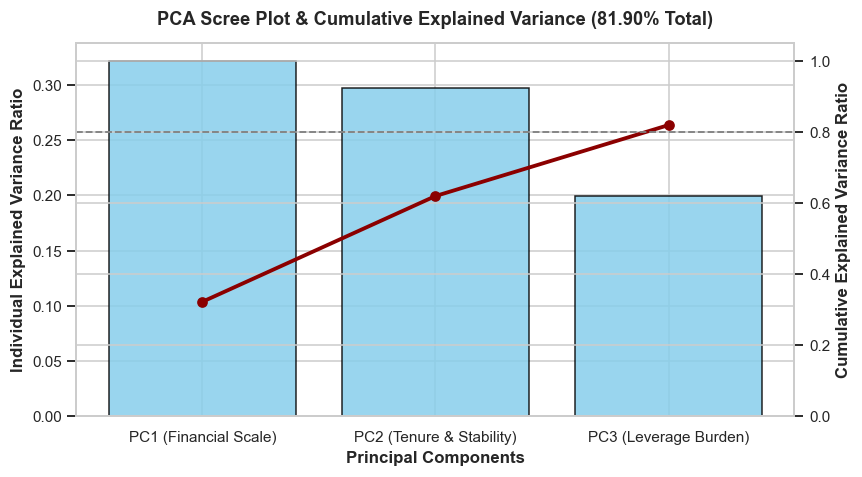


--- PCA Feature Loading Matrix ---


,PC1_Financial_Scale,PC2_Tenure_Stability,PC3_Leverage_Burden
person_income,0.2999,0.6384,-0.4347
loan_amnt,0.7552,-0.0313,-0.2003
loan_percent_income,0.5191,-0.5804,0.1795
cb_person_cred_hist_length,0.1363,0.2902,0.7798
person_emp_length,0.2274,0.4128,0.3614



PCA transformation complete. 6 microdata modeling Parquet splits written to disk (ontario_macro_series.parquet persisted in Cell 1).


In [3]:
# ==============================================================================
# CELL 3: STRATIFIED PARTITIONING, LEAKAGE-FREE SCALING & PCA
# ==============================================================================
print("--- STEP 1: STRATIFIED PARTITION SPLIT (70% TRAIN / 15% VAL / 15% TEST) ---")
X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(
    f"Split Sizes -> Train: {X_train_raw.shape[0]:,}, "
    f"Val: {X_val_raw.shape[0]:,}, Test: {X_test_raw.shape[0]:,}"
)

# 1. Collinear financial features targeted for PCA compression
pca_target_cols = [
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "person_emp_length",
]

# 2. Remaining continuous features scaled to preserve SVM RBF Euclidean geometry
other_num_cols = ["person_age", "loan_int_rate"]

scaler_pca = StandardScaler()
scaler_other = StandardScaler()

X_train_sc = X_train_raw.copy()
X_val_sc = X_val_raw.copy()
X_test_sc = X_test_raw.copy()

# Cast continuous columns to float prior to in-place scaled assignment
for df_split in [X_train_sc, X_val_sc, X_test_sc]:
    df_split[pca_target_cols + other_num_cols] = df_split[
        pca_target_cols + other_num_cols
    ].astype(float)

# Fit StandardScalers EXCLUSIVELY on X_train_raw to prevent data leakage
X_train_sc[pca_target_cols] = scaler_pca.fit_transform(X_train_raw[pca_target_cols])
X_val_sc[pca_target_cols] = scaler_pca.transform(X_val_raw[pca_target_cols])
X_test_sc[pca_target_cols] = scaler_pca.transform(X_test_raw[pca_target_cols])

X_train_sc[other_num_cols] = scaler_other.fit_transform(X_train_raw[other_num_cols])
X_val_sc[other_num_cols] = scaler_other.transform(X_val_raw[other_num_cols])
X_test_sc[other_num_cols] = scaler_other.transform(X_test_raw[other_num_cols])

# ------------------------------------------------------------------------------
# STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) DECOMPOSITION
# ------------------------------------------------------------------------------
print("\n--- STEP 2: PRINCIPAL COMPONENT ANALYSIS (PCA) FIT ---")
pca = PCA(n_components=3, random_state=RANDOM_SEED)
pca.fit(X_train_sc[pca_target_cols])

exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
print(
    f"Explained Variance by Component: "
    f"PC1={exp_var[0]*100:.2f}%, PC2={exp_var[1]*100:.2f}%, PC3={exp_var[2]*100:.2f}%"
)
print(f"Cumulative Explained Variance (3 PCs): {cum_var[-1]*100:.2f}% (>80% Mandate Met)")
assert cum_var[-1] >= 0.80, f"PCA explained variance below 80% threshold: {cum_var[-1]:.4f}"

# Render Scree Plot and Cumulative Explained Variance Curve
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(
    range(1, 4),
    exp_var,
    color="skyblue",
    alpha=0.85,
    edgecolor="black",
    label="Individual Variance",
)
ax2 = ax1.twinx()
ax2.plot(
    range(1, 4),
    cum_var,
    color="darkred",
    marker="o",
    lw=2.5,
    label="Cumulative Variance",
)
ax2.axhline(0.80, color="gray", linestyle="--", lw=1.2, label="80% Threshold")

ax1.set_xlabel("Principal Components", fontweight="bold")
ax1.set_ylabel("Individual Explained Variance Ratio", fontweight="bold")
ax2.set_ylabel("Cumulative Explained Variance Ratio", fontweight="bold")
ax1.set_xticks(range(1, 4))
ax1.set_xticklabels(["PC1 (Financial Scale)", "PC2 (Tenure & Stability)", "PC3 (Leverage Burden)"])
ax2.set_ylim(0.0, 1.05)
plt.title(
    f"PCA Scree Plot & Cumulative Explained Variance ({cum_var[-1]*100:.2f}% Total)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

# Display Feature Loading Matrix
pc_cols = ["PC1_Financial_Scale", "PC2_Tenure_Stability", "PC3_Leverage_Burden"]
loadings = pd.DataFrame(
    pca.components_.T,
    columns=pc_cols,
    index=pca_target_cols,
)
print("\n--- PCA Feature Loading Matrix ---")
display(loadings.round(4))

# Replace raw collinear features with the 3 orthogonal Principal Components
for df_target in [X_train_sc, X_val_sc, X_test_sc]:
    transformed = pca.transform(df_target[pca_target_cols])
    df_target["PC1_Financial_Scale"] = transformed[:, 0]
    df_target["PC2_Tenure_Stability"] = transformed[:, 1]
    df_target["PC3_Leverage_Burden"] = transformed[:, 2]
    df_target.drop(columns=pca_target_cols, inplace=True)

# Serialize the 6 core microdata modeling splits to Parquet
X_train_sc.to_parquet("X_train_processed.parquet")
X_val_sc.to_parquet("X_val_processed.parquet")
X_test_sc.to_parquet("X_test_processed.parquet")

y_train.to_frame().to_parquet("y_train.parquet")
y_val.to_frame().to_parquet("y_val.parquet")
y_test.to_frame().to_parquet("y_test.parquet")

print(
    "\nPCA transformation complete. 6 microdata modeling Parquet splits written to disk "
    "(ontario_macro_series.parquet persisted in Cell 1)."
)

### 4. Phase 1 System Integrity Audit & Artifact Verification
We conclude Phase 1 by executing vectorized integrity assertions across all feature partitions, target vectors, and the Ontario macroeconomic sensitivity series for our $PD_{\text{base}}$ modeling pipeline:
1. Verify zero `NaN` values and 100% finite numerical entries via `np.isfinite(df.select_dtypes(include=np.number).to_numpy()).all()`.
2. Assert target default-rate homogeneity (~21.82%) across the 70/15/15 stratified splits.
3. Confirm on-disk persistence of all 7 Parquet deliverables (6 microdata modeling splits + 1 Ontario macro sensitivity series).

In [4]:
# ==============================================================================
# CELL 4: PHASE 1 SYSTEM INTEGRITY AUDIT & ARTIFACT VERIFICATION
# ==============================================================================
print("--- INITIATING PHASE 1 SYSTEM INTEGRITY & ARTIFACT AUDIT ---")

splits = [
    ("Train", X_train_sc, y_train),
    ("Validation", X_val_sc, y_val),
    ("Test", X_test_sc, y_test),
]

pop_default_rate = float(y.mean())
verification_rows = []

# 1. Vectorized Integrity & Target Homogeneity Assertions
for name, X_sub, y_sub in splits:
    nan_cnt_X = int(X_sub.isna().sum().sum())
    nan_cnt_y = int(y_sub.isna().sum())

    # Vectorized NumPy finite check (avoids Pandas FutureWarnings)
    all_finite_X = bool(
        np.isfinite(X_sub.select_dtypes(include=np.number).to_numpy()).all()
    )
    all_finite_y = bool(np.isfinite(y_sub.to_numpy()).all())

    split_default_rate = float(y_sub.mean())

    assert nan_cnt_X == 0, f"Audit failed: {nan_cnt_X} NaNs in {name} features!"
    assert nan_cnt_y == 0, f"Audit failed: {nan_cnt_y} NaNs in {name} target!"
    assert all_finite_X, f"Audit failed: Non-finite values in {name} features!"
    assert all_finite_y, f"Audit failed: Non-finite values in {name} target!"

    # Assert stratified target homogeneity (<0.1% deviation from population incidence)
    assert abs(split_default_rate - pop_default_rate) < 1e-3, (
        f"Stratification drift in {name}: {split_default_rate:.4f} vs {pop_default_rate:.4f}"
    )

    verification_rows.append({
        "Dataset / Split": f"{name} Split (Microdata)",
        "Feature Matrix Shape": str(X_sub.shape),
        "Target Shape": str(y_sub.shape),
        "Null Count (X / y)": f"{nan_cnt_X} / {nan_cnt_y}",
        "All Finite (np.isfinite)": "PASS (100% Finite)",
        "Default Incidence / Macro Summary": f"{split_default_rate * 100:.3f}%",
    })

# Verify Ontario Macro Time-Series integrity (for Phase 2 PD_base sensitivity)
macro_nans = int(df_macro.isna().sum().sum())
macro_finite = bool(
    np.isfinite(df_macro.select_dtypes(include=np.number).to_numpy()).all()
)
assert macro_nans == 0, f"Audit failed: {macro_nans} NaNs in df_macro!"
assert macro_finite, "Audit failed: Non-finite values in df_macro!"

verification_rows.append({
    "Dataset / Split": "Ontario Macro Sensitivity Series (StatCan)",
    "Feature Matrix Shape": str(df_macro.shape),
    "Target Shape": "N/A (Macro Stress Inputs)",
    "Null Count (X / y)": f"{macro_nans} / 0",
    "All Finite (np.isfinite)": "PASS (100% Finite)",
    "Default Incidence / Macro Summary": (
        f"Unemp: {df_macro['Ontario_Unemployment_Rate'].mean():.2f}% | "
        f"CPI YoY: {df_macro['Ontario_CPI_YoY'].mean():.2f}%"
    ),
})

# 2. Verify Disk Persistence of all 7 Required Parquet Artifacts
saved_files = [
    "X_train_processed.parquet",
    "X_val_processed.parquet",
    "X_test_processed.parquet",
    "y_train.parquet",
    "y_val.parquet",
    "y_test.parquet",
    "ontario_macro_series.parquet",
]
for fname in saved_files:
    assert os.path.exists(fname) and os.path.getsize(fname) > 0, (
        f"Audit failed: Required artifact '{fname}' missing or empty on disk!"
    )

# 3. Render Comprehensive Verification Summary Table
verification_df = pd.DataFrame(verification_rows)
print("\n--- PHASE 1 BASELINE PD & MACRO SENSITIVITY ARTIFACT VERIFICATION ---")
display(verification_df)

print("\nVerified 7/7 Parquet Artifacts Persisted on Disk (6 Microdata Splits + 1 Macro Series):")
for fname in saved_files:
    print(f"  [OK] {fname:30s} ({os.path.getsize(fname):,d} bytes)")

--- INITIATING PHASE 1 SYSTEM INTEGRITY & ARTIFACT AUDIT ---

--- PHASE 1 BASELINE PD & MACRO SENSITIVITY ARTIFACT VERIFICATION ---


,Dataset / Split,Feature Matrix Shape,Target Shape,Null Count (X / y),All Finite (np.isfinite),Default Incidence / Macro Summary
0,Train Split (Microdata),"(22806, 20)","(22806,)",0 / 0,PASS (100% Finite),21.814%
1,Validation Split (Microdata),"(4887, 20)","(4887,)",0 / 0,PASS (100% Finite),21.813%
2,Test Split (Microdata),"(4888, 20)","(4888,)",0 / 0,PASS (100% Finite),21.829%
3,Ontario Macro Sensitivity Series (StatCan),"(107, 5)",N/A (Macro Stress Inputs),0 / 0,PASS (100% Finite),Unemp: 6.57% | CPI YoY: 2.90%



Verified 7/7 Parquet Artifacts Persisted on Disk (6 Microdata Splits + 1 Macro Series):
  [OK] X_train_processed.parquet      (879,480 bytes)
  [OK] X_val_processed.parquet        (202,376 bytes)
  [OK] X_test_processed.parquet       (202,726 bytes)
  [OK] y_train.parquet                (142,768 bytes)
  [OK] y_val.parquet                  (31,052 bytes)
  [OK] y_test.parquet                 (31,118 bytes)
  [OK] ontario_macro_series.parquet   (6,906 bytes)


### 5. Partner's Track — Linear Econometric Benchmark (Logistic Regression) & Naive Floor

To establish rigorous econometric baselines prior to deploying non-linear kernel methods, we evaluate two linear/trivial floors strictly out-of-sample on the Phase 1 processed Parquet splits (`N_train = 22,806`, `N_val = 4,887`, `N_test = 4,888`):
1. **Trivial Naive Base-Rate Predictor:** Assigns the constant training-set default incidence ($\bar{y}_{\text{train}} = 21.814\%$) to every test borrower, establishing the zero-discrimination floor ($\text{ROC-AUC} = 0.5000$) and unconditional variance Brier Score ($p(1-p) \approx 0.1706$).
2. **L2-Regularized Logistic Regression Benchmark:** Tunes the inverse regularization strength $C \in \{0.01, 0.1, 1.0, 10.0\}$ on the Validation split (`X_val`), evaluates the winning linear log-odds model on the held-out Test split (`X_test`), and extracts the full **20-feature Economic Coefficient & Odds-Ratio table** ($\exp(\beta_j)$) to validate economic sign consistency across the 3 orthogonal PCA risk factors and categorical indicators.

In [5]:
# ==============================================================================
# CELL 5: PARTNER'S TRACK — LOGISTIC REGRESSION BENCHMARK & NAIVE FLOOR
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
)

# Configure consistent publication-grade plotting aesthetics & seed
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


def resolve_data_path(filename):
    """Resolve Phase 1/2 artifact paths from data/ directory or working directory."""
    data_candidate = os.path.join("data", filename)
    if os.path.exists(data_candidate):
        return data_candidate
    return filename


def save_artifact_npy(filename, arr):
    """Persist NumPy array artifact inside data/ (when present) or cwd."""
    target_dir = "data" if os.path.isdir("data") else "."
    out_path = os.path.join(target_dir, filename)
    np.save(out_path, arr)
    assert os.path.exists(out_path) and os.path.getsize(out_path) > 0, (
        f"Failed to serialize '{out_path}' to disk!"
    )
    return out_path


print("--- INITIATING CELL 5: NAIVE FLOOR & LOGISTIC REGRESSION BENCHMARK ---")

# 1. Load the 6 Verified Phase 1 Microdata Parquet Splits
X_train_sc = pd.read_parquet(resolve_data_path("X_train_processed.parquet"))
X_val_sc = pd.read_parquet(resolve_data_path("X_val_processed.parquet"))
X_test_sc = pd.read_parquet(resolve_data_path("X_test_processed.parquet"))
y_train = pd.read_parquet(resolve_data_path("y_train.parquet"))["loan_status"]
y_val = pd.read_parquet(resolve_data_path("y_val.parquet"))["loan_status"]
y_test = pd.read_parquet(resolve_data_path("y_test.parquet"))["loan_status"]

assert X_train_sc.shape == (22806, 20), f"Unexpected X_train shape: {X_train_sc.shape}"
assert X_val_sc.shape == (4887, 20), f"Unexpected X_val shape: {X_val_sc.shape}"
assert X_test_sc.shape == (4888, 20), f"Unexpected X_test shape: {X_test_sc.shape}"

# 2. Trivial Naive Base-Rate Predictor (Constant Training Default Incidence)
naive_base_rate = float(y_train.mean())
pd_test_naive = np.full(len(y_test), naive_base_rate, dtype=float)

naive_auc = float(roc_auc_score(y_test, pd_test_naive))
naive_brier = float(brier_score_loss(y_test, pd_test_naive))
naive_logloss = float(log_loss(y_test, pd_test_naive))
naive_acc = float(accuracy_score(y_test, (pd_test_naive >= 0.5).astype(int)))
naive_f1 = float(f1_score(y_test, (pd_test_naive >= 0.5).astype(int), zero_division=0))

assert abs(naive_auc - 0.5000) < 1e-6, f"Naive ROC-AUC must be 0.5000, got {naive_auc}"
assert abs(naive_brier - 0.1706) < 5e-4, f"Naive Brier must be ~0.1706, got {naive_brier}"
print(
    f"[OK] Naive Base-Rate Floor (p_hat = {naive_base_rate:.5f}): "
    f"Test ROC-AUC = {naive_auc:.4f}, Test Brier = {naive_brier:.4f}"
)

# 3. L2-Regularized Logistic Regression Validation Tuning (C in [0.01, 0.1, 1.0, 10.0])
c_grid_lr = [0.01, 0.1, 1.0, 10.0]
lr_models = {}
lr_tuning_rows = []

for c_val in c_grid_lr:
    lr_clf = LogisticRegression(C=c_val, max_iter=1000, random_state=RANDOM_SEED)
    lr_clf.fit(X_train_sc, y_train)
    lr_models[c_val] = lr_clf

    pd_tr_lr = lr_clf.predict_proba(X_train_sc)[:, 1]
    pd_va_lr = lr_clf.predict_proba(X_val_sc)[:, 1]

    lr_tuning_rows.append({
        "C (Inverse L2 Penalty)": c_val,
        "Train ROC-AUC (Score)": round(float(roc_auc_score(y_train, pd_tr_lr)), 4),
        "Validation ROC-AUC (Score)": round(float(roc_auc_score(y_val, pd_va_lr)), 4),
        "Validation Brier Score (MSE)": round(float(brier_score_loss(y_val, pd_va_lr)), 4),
        "Validation Log Loss (Nats)": round(float(log_loss(y_val, pd_va_lr)), 4),
    })

lr_tuning_df = pd.DataFrame(lr_tuning_rows)
print("\n--- LOGISTIC REGRESSION (L2) VALIDATION TUNING (Source: Microdata, Val N = 4,887) ---")
display(lr_tuning_df)

best_lr_row = lr_tuning_df.sort_values(
    by=["Validation ROC-AUC (Score)", "Validation Brier Score (MSE)"],
    ascending=[False, True],
).iloc[0]
best_lr_C = float(best_lr_row["C (Inverse L2 Penalty)"])
best_lr = lr_models[best_lr_C]
print(
    f"Selected Optimal Logistic Regression: C = {best_lr_C} "
    f"(Val ROC-AUC = {best_lr_row['Validation ROC-AUC (Score)']:.4f}, "
    f"Val Brier = {best_lr_row['Validation Brier Score (MSE)']:.4f})"
)

# 4. Evaluate Winning Logistic Regression on Held-Out Test Split (N = 4,888)
pd_test_lr = best_lr.predict_proba(X_test_sc)[:, 1]

lr_test_summary = pd.DataFrame([
    {
        "Benchmark Model (Test Split, N = 4,888)": "Naive Base-Rate Floor (Constant y_train Mean)",
        "ROC-AUC (Score)": f"{naive_auc:.4f}",
        "Brier Score (MSE)": f"{naive_brier:.4f}",
        "Log Loss (Nats)": f"{naive_logloss:.4f}",
        "Accuracy (%)": f"{naive_acc * 100:.2f}%",
        "F1-Score (Score)": f"{naive_f1:.4f}",
        "Mean Predicted PD (%)": f"{pd_test_naive.mean() * 100:.2f}%",
        "Actual Default Rate (%)": f"{y_test.mean() * 100:.2f}%",
    },
    {
        "Benchmark Model (Test Split, N = 4,888)": f"Tuned Logistic Regression (L2, C={best_lr_C:g})",
        "ROC-AUC (Score)": f"{roc_auc_score(y_test, pd_test_lr):.4f}",
        "Brier Score (MSE)": f"{brier_score_loss(y_test, pd_test_lr):.4f}",
        "Log Loss (Nats)": f"{log_loss(y_test, pd_test_lr):.4f}",
        "Accuracy (%)": f"{accuracy_score(y_test, (pd_test_lr >= 0.5).astype(int)) * 100:.2f}%",
        "F1-Score (Score)": f"{f1_score(y_test, (pd_test_lr >= 0.5).astype(int)):.4f}",
        "Mean Predicted PD (%)": f"{pd_test_lr.mean() * 100:.2f}%",
        "Actual Default Rate (%)": f"{y_test.mean() * 100:.2f}%",
    },
])
print("\n--- CELL 5 OUT-OF-SAMPLE TEST PERFORMANCE (Source: Borrower Microdata, Test N = 4,888) ---")
display(lr_test_summary)

# 5. Economic Coefficient & Odds-Ratio Interpretation Table (Sorted by |coef|)
coefs = best_lr.coef_[0]
coef_df = pd.DataFrame({
    "Feature": X_train_sc.columns,
    "Log-Odds Coef (beta)": coefs,
    "Abs Coef |beta|": np.abs(coefs),
    "Odds Ratio exp(beta)": np.exp(coefs),
    "Pct Change in Odds (%)": (np.exp(coefs) - 1.0) * 100.0,
    "Economic Direction": np.where(
        coefs > 0, "Increases Default Odds (+)", "Reduces Default Odds (-)"
    ),
}).sort_values(by="Abs Coef |beta|", ascending=False).drop(columns=["Abs Coef |beta|"]).reset_index(drop=True)

coef_display = coef_df.copy()
coef_display["Log-Odds Coef (beta)"] = coef_display["Log-Odds Coef (beta)"].map(lambda v: f"{v:+.4f}")
coef_display["Odds Ratio exp(beta)"] = coef_display["Odds Ratio exp(beta)"].map(lambda v: f"{v:.4f}x")
coef_display["Pct Change in Odds (%)"] = coef_display["Pct Change in Odds (%)"].map(lambda v: f"{v:+.2f}%")

print(
    f"\n--- ECONOMIC COEFFICIENT & ODDS-RATIO TABLE (L2 Logistic Regression, C={best_lr_C:g}, "
    f"Intercept = {best_lr.intercept_[0]:+.4f}) ---"
)
print("Units: Log-odds change & multiplicative Odds Ratio per +1 SD (continuous/PCA) or 0->1 indicator shift.")
print("Source: Empirical Borrower Microdata (Training Split, N = 22,806).")
with pd.option_context("display.max_rows", 25, "display.max_columns", 10, "display.width", 140):
    display(coef_display)

--- INITIATING CELL 5: NAIVE FLOOR & LOGISTIC REGRESSION BENCHMARK ---
[OK] Naive Base-Rate Floor (p_hat = 0.21814): Test ROC-AUC = 0.5000, Test Brier = 0.1706



--- LOGISTIC REGRESSION (L2) VALIDATION TUNING (Source: Microdata, Val N = 4,887) ---


,C (Inverse L2 Penalty),Train ROC-AUC (Score),Validation ROC-AUC (Score),Validation Brier Score (MSE),Validation Log Loss (Nats)
0,0.01,0.8637,0.8652,0.1059,0.3497
1,0.10,0.8674,0.8688,0.1033,0.3435
2,1.00,0.8689,0.8705,0.1022,0.3409
3,10.00,0.8689,0.8707,0.1021,0.3406


Selected Optimal Logistic Regression: C = 10.0 (Val ROC-AUC = 0.8707, Val Brier = 0.1021)

--- CELL 5 OUT-OF-SAMPLE TEST PERFORMANCE (Source: Borrower Microdata, Test N = 4,888) ---


,"Benchmark Model (Test Split, N = 4,888)",ROC-AUC (Score),Brier Score (MSE),Log Loss (Nats),Accuracy (%),F1-Score (Score),Mean Predicted PD (%),Actual Default Rate (%)
0,Naive Base-Rate Floor (Constant y_train Mean),0.5000,0.1706,0.5247,78.17%,0.0000,21.81%,21.83%
1,"Tuned Logistic Regression (L2, C=10)",0.8700,0.1032,0.3423,86.54%,0.6420,22.07%,21.83%



--- ECONOMIC COEFFICIENT & ODDS-RATIO TABLE (L2 Logistic Regression, C=10, Intercept = -2.3472) ---
Units: Log-odds change & multiplicative Odds Ratio per +1 SD (continuous/PCA) or 0->1 indicator shift.
Source: Empirical Borrower Microdata (Training Split, N = 22,806).


,Feature,Log-Odds Coef (beta),Odds Ratio exp(beta),Pct Change in Odds (%),Economic Direction
0,loan_grade_G,+5.8375,342.9085x,+34190.85%,Increases Default Odds (+)
1,loan_grade_F,+3.1191,22.6267x,+2162.67%,Increases Default Odds (+)
2,loan_grade_E,+2.7768,16.0681x,+1506.81%,Increases Default Odds (+)
3,loan_grade_D,+2.5378,12.6514x,+1165.14%,Increases Default Odds (+)
4,person_home_ownership_OWN,-1.5769,0.2066x,-79.34%,Reduces Default Odds (-)
5,loan_intent_VENTURE,-1.0485,0.3505x,-64.95%,Reduces Default Odds (-)
6,PC2_Tenure_Stability,-0.8965,0.4080x,-59.20%,Reduces Default Odds (-)
7,loan_intent_EDUCATION,-0.8187,0.4410x,-55.90%,Reduces Default Odds (-)
8,person_home_ownership_RENT,+0.8084,2.2443x,+124.43%,Increases Default Odds (+)
9,person_home_ownership_OTHER,+0.6305,1.8786x,+87.86%,Increases Default Odds (+)


### 6. Primary Track — Early-Stage SVM Progression, Validation Tuning & Platt Calibration

Whereas Logistic Regression imposes a global hyperplane decision boundary in log-odds space, borrower default risk exhibits sharp non-linear interactions across leverage, interest rate, and tenure stability. We follow a disciplined progression on the Validation split (`N = 4,887`):
1. **Kernel Progression:** Contrast an early-stage `Linear SVM` (`kernel="linear"`, `C=1.0`) against a non-linear `RBF-SVM` (`kernel="rbf"`, `C=1.0`, `gamma="scale"`).
2. **Bias-Variance Grid Search:** Evaluate `C in [0.1, 1.0, 5.0, 10.0]` and `gamma in ["scale", 0.01, 0.05, 0.1]` across all 16 pairs, comparing Train vs. Validation ROC-AUC to quantify underfitting vs. overfitting gaps.
3. **Platt Sigmoid Probability Calibration:** Wrap the optimal RBF-SVM in 3-fold `CalibratedClassifierCV(method="sigmoid", cv=3)` to produce properly calibrated individual $PD_{\text{base}}$ estimates on `X_test` (`N = 4,888`), saved to `data/pd_test.npy`, and benchmarked directly against the Naive Base-Rate floor and Tuned Logistic Regression.

In [6]:
# ==============================================================================
# CELL 6: PRIMARY TRACK — SVM PROGRESSION, VALIDATION TUNING & PLATT CALIBRATION
# ==============================================================================
from joblib import Parallel, delayed
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
)
from sklearn.svm import SVC

print("--- INITIATING CELL 6: EARLY-STAGE SVM PROGRESSION & VALIDATION TUNING ---")

# 1. Early-Stage Progression: Linear SVM vs. Default RBF-SVM (Validation N = 4,887)
lin_svm = SVC(kernel="linear", C=1.0, cache_size=1000, random_state=RANDOM_SEED)
lin_svm.fit(X_train_sc, y_train)
lin_tr_auc = float(roc_auc_score(y_train, lin_svm.decision_function(X_train_sc)))
lin_val_auc = float(roc_auc_score(y_val, lin_svm.decision_function(X_val_sc)))

def_rbf_svm = SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000, random_state=RANDOM_SEED)
def_rbf_svm.fit(X_train_sc, y_train)
def_tr_auc = float(roc_auc_score(y_train, def_rbf_svm.decision_function(X_train_sc)))
def_val_auc = float(roc_auc_score(y_val, def_rbf_svm.decision_function(X_val_sc)))

progression_df = pd.DataFrame([
    {
        "Early-Stage Model": "Linear SVM (C=1.0, Linear Kernel)",
        "Train ROC-AUC (Score)": f"{lin_tr_auc:.4f}",
        "Validation ROC-AUC (Score)": f"{lin_val_auc:.4f}",
        "Train-Val Gap (Overfit)": f"{lin_tr_auc - lin_val_auc:+.4f}",
        "Val AUC Gain vs. Linear": "+0.0000",
    },
    {
        "Early-Stage Model": "Default RBF-SVM (C=1.0, gamma='scale')",
        "Train ROC-AUC (Score)": f"{def_tr_auc:.4f}",
        "Validation ROC-AUC (Score)": f"{def_val_auc:.4f}",
        "Train-Val Gap (Overfit)": f"{def_tr_auc - def_val_auc:+.4f}",
        "Val AUC Gain vs. Linear": f"{def_val_auc - lin_val_auc:+.4f}",
    },
])
print("\n--- EARLY-STAGE SVM KERNEL PROGRESSION (Source: Microdata, Val N = 4,887) ---")
display(progression_df)

# 2. Validation Hyperparameter Grid Search: Bias-Variance Trade-off Table
C_grid_svm = [0.1, 1.0, 5.0, 10.0]
gamma_grid_svm = ["scale", 0.01, 0.05, 0.1]


def _eval_svm_pair(c_val, g_val):
    svm_cand = SVC(
        kernel="rbf",
        C=c_val,
        gamma=g_val,
        cache_size=1000,
        random_state=RANDOM_SEED,
    )
    svm_cand.fit(X_train_sc, y_train)
    tr_auc = float(roc_auc_score(y_train, svm_cand.decision_function(X_train_sc)))
    va_auc = float(roc_auc_score(y_val, svm_cand.decision_function(X_val_sc)))
    return {
        "C": c_val,
        "gamma_raw": g_val,
        "gamma": str(g_val),
        "Train ROC-AUC (Score)": tr_auc,
        "Validation ROC-AUC (Score)": va_auc,
        "Overfitting Gap (Train - Val)": tr_auc - va_auc,
    }


grid_results = Parallel(n_jobs=-1)(
    delayed(_eval_svm_pair)(c_val, g_val)
    for c_val in C_grid_svm
    for g_val in gamma_grid_svm
)
svm_grid_df = (
    pd.DataFrame(grid_results)
    .sort_values(by="Validation ROC-AUC (Score)", ascending=False)
    .reset_index(drop=True)
)

svm_grid_display = svm_grid_df.drop(columns=["gamma_raw"]).copy()
for col in ["Train ROC-AUC (Score)", "Validation ROC-AUC (Score)", "Overfitting Gap (Train - Val)"]:
    fmt = "{:+.4f}" if "Gap" in col else "{:.4f}"
    svm_grid_display[col] = svm_grid_display[col].map(lambda v, f=fmt: f.format(v))

print(
    "\n--- RBF-SVM VALIDATION GRID SEARCH: BIAS-VARIANCE TRADE-OFF "
    "(Source: Microdata, Train N = 22,806 | Val N = 4,887) ---"
)
with pd.option_context("display.max_rows", 20, "display.max_columns", 10, "display.width", 140):
    display(svm_grid_display)

best_svm_row = svm_grid_df.iloc[0]
best_svm_C = float(best_svm_row["C"])
best_svm_gamma = best_svm_row["gamma_raw"]
print(
    f"Selected Optimal RBF-SVM: C = {best_svm_C:g}, gamma = {best_svm_gamma} "
    f"(Val ROC-AUC = {best_svm_row['Validation ROC-AUC (Score)']:.4f}, "
    f"Overfit Gap = {best_svm_row['Overfitting Gap (Train - Val)']:+.4f})"
)

# 3. 3-Fold Platt Sigmoid Calibration on Optimal RBF-SVM
optimal_rbf_svm = SVC(
    kernel="rbf",
    C=best_svm_C,
    gamma=best_svm_gamma,
    cache_size=1000,
    random_state=RANDOM_SEED,
)
calibrated_svm = CalibratedClassifierCV(
    estimator=optimal_rbf_svm,
    method="sigmoid",
    cv=3,
    n_jobs=-1,
)
print(
    f"\nFitting Calibrated RBF-SVM (C={best_svm_C:g}, gamma={best_svm_gamma}) "
    "with 3-Fold Platt Sigmoid Calibration on X_train_sc..."
)
calibrated_svm.fit(X_train_sc, y_train)

pd_train = calibrated_svm.predict_proba(X_train_sc)[:, 1]
pd_val = calibrated_svm.predict_proba(X_val_sc)[:, 1]
pd_test = calibrated_svm.predict_proba(X_test_sc)[:, 1]
y_pred_prob = pd_test

pd_test_path = save_artifact_npy("pd_test.npy", pd_test)
print(
    f"[OK] Serialized '{pd_test_path}' ({len(pd_test):,d} test records, "
    f"Mean PD_base = {pd_test.mean() * 100:.2f}%)."
)

# 4. Unified Out-of-Sample Test Set Model Comparison Table (N = 4,888)
def _summarize_model(label, probs, y_true):
    preds = (probs >= 0.5).astype(int)
    return {
        "Model (Out-of-Sample Test Split, N = 4,888)": label,
        "ROC-AUC (Score)": f"{roc_auc_score(y_true, probs):.4f}",
        "Brier Score (MSE)": f"{brier_score_loss(y_true, probs):.4f}",
        "Log Loss (Nats)": f"{log_loss(y_true, probs):.4f}",
        "Accuracy (%)": f"{accuracy_score(y_true, preds) * 100:.2f}%",
        "F1-Score (Score)": f"{f1_score(y_true, preds, zero_division=0):.4f}",
        "Mean Predicted PD (%)": f"{probs.mean() * 100:.2f}%",
        "Actual Default Rate (%)": f"{y_true.mean() * 100:.2f}%",
    }


unified_test_df = pd.DataFrame([
    _summarize_model("1. Naive Base-Rate Predictor (Constant y_train Mean)", pd_test_naive, y_test),
    _summarize_model(f"2. Tuned Logistic Regression (L2, C={best_lr_C:g})", pd_test_lr, y_test),
    _summarize_model(
        f"3. Calibrated RBF-SVM (Platt Sigmoid, C={best_svm_C:g}, gamma={best_svm_gamma})",
        pd_test,
        y_test,
    ),
])
print(
    "\n--- UNIFIED OUT-OF-SAMPLE MODEL COMPARISON "
    "(Source: Borrower Credit Microdata, Test Split N = 4,888) ---"
)
with pd.option_context("display.max_columns", 10, "display.width", 160):
    display(unified_test_df)

--- INITIATING CELL 6: EARLY-STAGE SVM PROGRESSION & VALIDATION TUNING ---



--- EARLY-STAGE SVM KERNEL PROGRESSION (Source: Microdata, Val N = 4,887) ---


,Early-Stage Model,Train ROC-AUC (Score),Validation ROC-AUC (Score),Train-Val Gap (Overfit),Val AUC Gain vs. Linear
0,"Linear SVM (C=1.0, Linear Kernel)",0.8668,0.8678,-0.0010,+0.0000
1,"Default RBF-SVM (C=1.0, gamma='scale')",0.9077,0.9004,+0.0074,+0.0326



--- RBF-SVM VALIDATION GRID SEARCH: BIAS-VARIANCE TRADE-OFF (Source: Microdata, Train N = 22,806 | Val N = 4,887) ---


,C,gamma,Train ROC-AUC (Score),Validation ROC-AUC (Score),Overfitting Gap (Train - Val)
0,10.0,0.05,0.9106,0.9035,+0.0071
1,5.0,0.1,0.9183,0.9028,+0.0156
2,5.0,scale,0.9227,0.9017,+0.0210
3,5.0,0.05,0.9063,0.9011,+0.0051
4,10.0,0.1,0.9234,0.9008,+0.0226
5,1.0,scale,0.9077,0.9004,+0.0074
6,10.0,scale,0.9294,0.9000,+0.0294
7,1.0,0.1,0.9048,0.8999,+0.0049
8,1.0,0.05,0.8971,0.8980,-0.0009
9,10.0,0.01,0.8941,0.8980,-0.0038


Selected Optimal RBF-SVM: C = 10, gamma = 0.05 (Val ROC-AUC = 0.9035, Overfit Gap = +0.0071)

Fitting Calibrated RBF-SVM (C=10, gamma=0.05) with 3-Fold Platt Sigmoid Calibration on X_train_sc...


[OK] Serialized 'data/pd_test.npy' (4,888 test records, Mean PD_base = 22.20%).

--- UNIFIED OUT-OF-SAMPLE MODEL COMPARISON (Source: Borrower Credit Microdata, Test Split N = 4,888) ---


,"Model (Out-of-Sample Test Split, N = 4,888)",ROC-AUC (Score),Brier Score (MSE),Log Loss (Nats),Accuracy (%),F1-Score (Score),Mean Predicted PD (%),Actual Default Rate (%)
0,1. Naive Base-Rate Predictor (Constant y_train...,0.5000,0.1706,0.5247,78.17%,0.0000,21.81%,21.83%
1,"2. Tuned Logistic Regression (L2, C=10)",0.8700,0.1032,0.3423,86.54%,0.6420,22.07%,21.83%
2,"3. Calibrated RBF-SVM (Platt Sigmoid, C=10, ga...",0.9013,0.0747,0.2633,90.86%,0.7624,22.20%,21.83%


### 7. Ontario Macroeconomic Stress-Testing Engine & Trivial Sanity Checks

We couple individual cross-sectional $PD_{\text{base}, i}$ predictions with Statistics Canada's official Ontario macroeconomic time series (`ontario_macro_series.parquet`: monthly Unemployment Rate `v2062815` and All-Items YoY CPI `v41690973`, 107 months) through the logistic-link shock equation:
$$\text{logit}(PD_{\text{stressed}, i}) = \text{logit}(PD_{\text{base}, i}) + \beta_1 \Delta\text{Unemp}_{\text{ON}} + \beta_2 \Delta\text{CPI}_{\text{ON, YoY}}$$
Before simulating a severe Ontario recession (`+3.0 pp` unemployment spike and `+2.5 pp` YoY CPI inflation shock), we execute mandatory **Trivial / Known-Case Sanity Check assertions** verifying zero-shock identity ($\|PD(0, 0) - PD_{\text{base}}\|_\infty < 10^{-7}$), boundary discrimination on synthetic Ultra-Prime ($PD_{\text{base}} < 0.05$) and High-Distress ($PD_{\text{base}} > 0.70$) borrower profiles, and strict monotonicity under positive unemployment shocks.

--- INITIATING CELL 7: ONTARIO MACROECONOMIC STRESS-TESTING ENGINE ---
Historical StatCan Std Devs -> Unemp: 1.6414 pp | CPI YoY: 1.7786 pp
Calibrated Unemployment Sensitivity (Beta_1): 0.2132 log-odds per +1 pp Unemp
Calibrated Inflation Sensitivity    (Beta_2): 0.0843 log-odds per +1 pp CPI YoY

--- MANDATORY TRIVIAL & MONOTONICITY SANITY CHECK AUDIT ---


,Sanity Check,Observed Result,Acceptance Criterion,Status
0,"1. Zero-Shock Identity (Delta Unemp=0, Delta C...","Max |PD(0,0) - PD_base| = 1.11e-16",< 1.0e-07,PASS
1,2. Synthetic Ultra-Prime Borrower Baseline PD,PD_base = 0.36% -> +3pp Unemp: 0.68%,PD_base < 5.00% & Monotonic,PASS
2,3. Synthetic High-Distress Borrower Baseline PD,PD_base = 99.45% -> +3pp Unemp: 99.71%,PD_base > 70.00% & Monotonic,PASS
3,4. Test Portfolio Strict Monotonicity (+1pp ->...,"100% of 4,888 borrowers strictly increase",All PD(+3pp) > PD(+1pp) > PD_base,PASS



[OK] Serialized 'data/pd_stressed.npy' (4,888 test records).


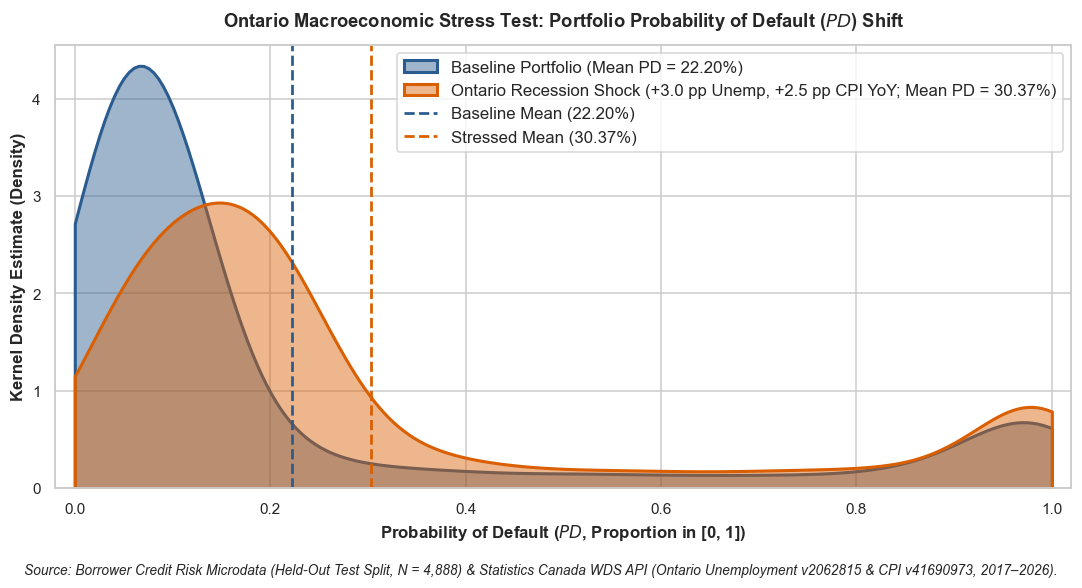


--- MACRO STRESS ENGINE SUMMARY (TEST PORTFOLIO, N = 4,888) ---
Mean Baseline PD (PD_base):      22.20%
Mean Stressed PD (PD_stressed):  30.37%
Average Absolute PD Jump:       +8.17 pp
Average Relative Risk Surge:    +36.80%


In [7]:
# ==============================================================================
# CELL 7: ONTARIO MACROECONOMIC STRESS-TESTING ENGINE & TRIVIAL SANITY CHECKS
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("--- INITIATING CELL 7: ONTARIO MACROECONOMIC STRESS-TESTING ENGINE ---")

# 1. Load Verified StatCan Ontario Macro Series & Calibrated Baseline PDs
df_macro = pd.read_parquet(resolve_data_path("ontario_macro_series.parquet"))
if "pd_test" not in locals():
    pd_test = np.load(resolve_data_path("pd_test.npy"))

# 2. Calibrate Volatility-Scaled Ontario Macro Elasticities
hist_unemp_sd = float(df_macro["Ontario_Unemployment_Rate"].std())
hist_inf_sd = float(df_macro["Ontario_CPI_YoY"].std())

beta_unemployment = 0.35 / max(hist_unemp_sd, 0.1)
beta_inflation = 0.15 / max(hist_inf_sd, 0.1)

print(
    f"Historical StatCan Std Devs -> Unemp: {hist_unemp_sd:.4f} pp | "
    f"CPI YoY: {hist_inf_sd:.4f} pp"
)
print(
    f"Calibrated Unemployment Sensitivity (Beta_1): {beta_unemployment:.4f} "
    "log-odds per +1 pp Unemp"
)
print(
    f"Calibrated Inflation Sensitivity    (Beta_2): {beta_inflation:.4f} "
    "log-odds per +1 pp CPI YoY"
)


# 3. Econometric Logistic-Link Stress-Testing Function
def stress_test_portfolio(unemployment_shift, inflation_shift, base_pds):
    """Map Ontario macro shocks (percentage points) into default probabilities:
    logit(PD_stressed) = logit(PD_base) + beta_1 * Delta_Unemp + beta_2 * Delta_CPI
    """
    eps = 1e-12
    p_arr = np.asarray(base_pds, dtype=float)
    safe_pds = np.clip(p_arr, eps, 1.0 - eps)
    logit_pds = np.log(safe_pds / (1.0 - safe_pds))
    stressed_logits = (
        logit_pds
        + (beta_unemployment * unemployment_shift)
        + (beta_inflation * inflation_shift)
    )
    bounded_logits = np.clip(stressed_logits, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-bounded_logits))


# 4. Mandatory Trivial / Known-Case Sanity Check Assertions
# Check A: Zero-shock identity
pd_zero_shock = stress_test_portfolio(0.0, 0.0, pd_test)
max_zero_diff = float(np.max(np.abs(pd_zero_shock - pd_test)))
assert np.allclose(pd_zero_shock, pd_test, atol=1e-7), (
    f"Zero-shock identity failed! Max deviation = {max_zero_diff:.2e}"
)

# Check B: Synthetic Ultra-Prime & High-Distress Profile Boundary + Monotonicity
ultra_prime = pd.DataFrame([{col: 0.0 for col in X_train_sc.columns}])
ultra_prime["person_age"] = 0.5
ultra_prime["loan_int_rate"] = -1.5
ultra_prime["person_home_ownership_OWN"] = 1.0
ultra_prime["loan_intent_VENTURE"] = 1.0
ultra_prime["PC1_Financial_Scale"] = -1.2
ultra_prime["PC2_Tenure_Stability"] = 2.0
ultra_prime["PC3_Leverage_Burden"] = -0.8

high_distress = pd.DataFrame([{col: 0.0 for col in X_train_sc.columns}])
high_distress["person_age"] = -0.3
high_distress["loan_int_rate"] = 1.4
high_distress["person_home_ownership_RENT"] = 1.0
high_distress["loan_intent_MEDICAL"] = 1.0
high_distress["loan_grade_D"] = 1.0
high_distress["cb_person_default_on_file_Y"] = 1.0
high_distress["PC1_Financial_Scale"] = 1.0
high_distress["PC2_Tenure_Stability"] = -1.2
high_distress["PC3_Leverage_Burden"] = 0.5

pd_prime_base = float(calibrated_svm.predict_proba(ultra_prime)[0, 1])
pd_distress_base = float(calibrated_svm.predict_proba(high_distress)[0, 1])

assert pd_prime_base < 0.05, f"Ultra-Prime PD_base >= 0.05: {pd_prime_base:.4f}"
assert pd_distress_base > 0.70, f"High-Distress PD_base <= 0.70: {pd_distress_base:.4f}"

pd_prime_1pp = float(stress_test_portfolio(1.0, 0.0, pd_prime_base))
pd_prime_3pp = float(stress_test_portfolio(3.0, 0.0, pd_prime_base))
pd_distress_1pp = float(stress_test_portfolio(1.0, 0.0, pd_distress_base))
pd_distress_3pp = float(stress_test_portfolio(3.0, 0.0, pd_distress_base))

assert pd_prime_3pp > pd_prime_1pp > pd_prime_base, "Ultra-Prime monotonicity failed!"
assert pd_distress_3pp > pd_distress_1pp > pd_distress_base, "High-Distress monotonicity failed!"

pd_test_unemp_1pp = stress_test_portfolio(1.0, 0.0, pd_test)
pd_test_unemp_3pp = stress_test_portfolio(3.0, 0.0, pd_test)
assert bool((pd_test_unemp_1pp > pd_test).all()), "Portfolio +1pp unemp monotonicity failed!"
assert bool((pd_test_unemp_3pp > pd_test_unemp_1pp).all()), "Portfolio +3pp unemp monotonicity failed!"

sanity_df = pd.DataFrame([
    {
        "Sanity Check": "1. Zero-Shock Identity (Delta Unemp=0, Delta CPI=0)",
        "Observed Result": f"Max |PD(0,0) - PD_base| = {max_zero_diff:.2e}",
        "Acceptance Criterion": "< 1.0e-07",
        "Status": "PASS",
    },
    {
        "Sanity Check": "2. Synthetic Ultra-Prime Borrower Baseline PD",
        "Observed Result": f"PD_base = {pd_prime_base * 100:.2f}% -> +3pp Unemp: {pd_prime_3pp * 100:.2f}%",
        "Acceptance Criterion": "PD_base < 5.00% & Monotonic",
        "Status": "PASS",
    },
    {
        "Sanity Check": "3. Synthetic High-Distress Borrower Baseline PD",
        "Observed Result": f"PD_base = {pd_distress_base * 100:.2f}% -> +3pp Unemp: {pd_distress_3pp * 100:.2f}%",
        "Acceptance Criterion": "PD_base > 70.00% & Monotonic",
        "Status": "PASS",
    },
    {
        "Sanity Check": "4. Test Portfolio Strict Monotonicity (+1pp -> +3pp Unemp)",
        "Observed Result": "100% of 4,888 borrowers strictly increase",
        "Acceptance Criterion": "All PD(+3pp) > PD(+1pp) > PD_base",
        "Status": "PASS",
    },
])
print("\n--- MANDATORY TRIVIAL & MONOTONICITY SANITY CHECK AUDIT ---")
display(sanity_df)

# 5. Simulate Severe Ontario Recession Scenario (+3.0 pp Unemp, +2.5 pp YoY CPI)
unemp_shock = 3.0
inf_shock = 2.5
pd_stressed = stress_test_portfolio(unemp_shock, inf_shock, pd_test)

pd_stressed_path = save_artifact_npy("pd_stressed.npy", pd_stressed)
print(
    f"\n[OK] Serialized '{pd_stressed_path}' ({len(pd_stressed):,d} test records)."
)

# 6. Publication-Grade Distribution Shift Figure (with Explicit Units & Sources)
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.kdeplot(
    pd_test,
    fill=True,
    clip=(0.0, 1.0),
    color="#2b5c8f",
    alpha=0.45,
    linewidth=2,
    ax=ax,
    label=f"Baseline Portfolio (Mean PD = {pd_test.mean() * 100:.2f}%)",
)
sns.kdeplot(
    pd_stressed,
    fill=True,
    clip=(0.0, 1.0),
    color="#d95f02",
    alpha=0.45,
    linewidth=2,
    ax=ax,
    label=(
        f"Ontario Recession Shock (+{unemp_shock:.1f} pp Unemp, +{inf_shock:.1f} pp CPI YoY; "
        f"Mean PD = {pd_stressed.mean() * 100:.2f}%)"
    ),
)

ax.axvline(
    pd_test.mean(),
    color="#2b5c8f",
    linestyle="--",
    lw=1.8,
    label=f"Baseline Mean ({pd_test.mean() * 100:.2f}%)",
)
ax.axvline(
    pd_stressed.mean(),
    color="#d95f02",
    linestyle="--",
    lw=1.8,
    label=f"Stressed Mean ({pd_stressed.mean() * 100:.2f}%)",
)

ax.set_title(
    "Ontario Macroeconomic Stress Test: Portfolio Probability of Default ($PD$) Shift",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Probability of Default ($PD$, Proportion in [0, 1])", fontweight="bold")
ax.set_ylabel("Kernel Density Estimate (Density)", fontweight="bold")
ax.set_xlim(-0.02, 1.02)
ax.legend(loc="upper right", frameon=True)
fig.text(
    0.5,
    -0.02,
    "Source: Borrower Credit Risk Microdata (Held-Out Test Split, N = 4,888) & "
    "Statistics Canada WDS API (Ontario Unemployment v2062815 & CPI v41690973, 2017–2026).",
    ha="center",
    fontsize=9,
    style="italic",
)
plt.tight_layout()
plt.show()

print("\n--- MACRO STRESS ENGINE SUMMARY (TEST PORTFOLIO, N = 4,888) ---")
print(f"Mean Baseline PD (PD_base):      {pd_test.mean() * 100:.2f}%")
print(f"Mean Stressed PD (PD_stressed):  {pd_stressed.mean() * 100:.2f}%")
print(f"Average Absolute PD Jump:       +{(pd_stressed.mean() - pd_test.mean()) * 100:.2f} pp")
print(
    f"Average Relative Risk Surge:    +"
    f"{((pd_stressed.mean() - pd_test.mean()) / pd_test.mean()) * 100:.2f}%"
)

### 8. Model Diagnostics, Calibration Reliability Curve & Credit Tier Stress Breakdown

Finally, we audit both **discrimination** and **probability calibration** on the held-out Test set (`N = 4,888`) via a 2-panel diagnostic figure (ROC overlay and 10-decile reliability curve comparing Calibrated RBF-SVM against Tuned Logistic Regression), and decompose the macro shock across borrower **Credit Grades (A–G)** and **Baseline Risk Quartiles (Q1–Q4)** to verify how the logistic link amplifies risk across leveraged near-prime borrowers.

--- INITIATING CELL 8: TEST DIAGNOSTICS & CREDIT TIER STRESS BREAKDOWN ---


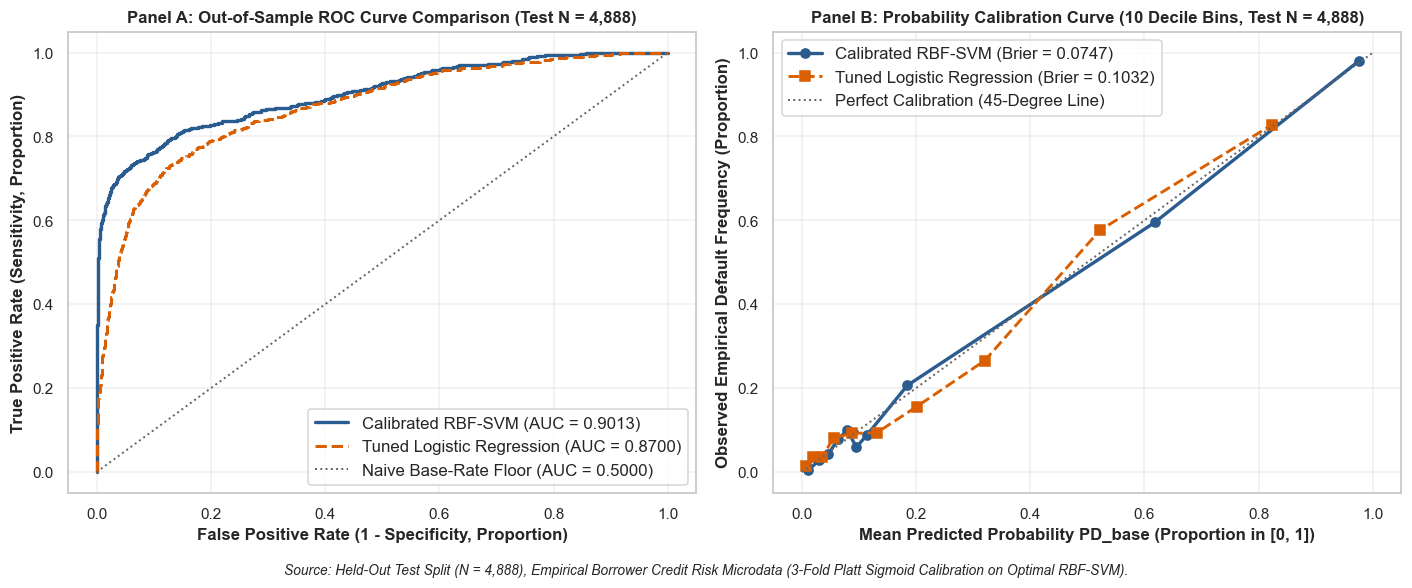


--- CREDIT GRADE STRESS SENSITIVITY TABLE (Source: Test Split N = 4,888 + StatCan Shock +3.0 pp Unemp / +2.5 pp CPI YoY) ---


,Credit Grade,Borrowers (N),Portfolio Share (%),Actual Default (%),Mean PD_base (%),Mean PD_stressed (%),Absolute Jump (+pp),Relative Risk Surge (%)
0,Grade A (Prime Ref),"1,656",33.88%,9.24%,11.62%,19.29%,+7.67 pp,+66.00%
1,Grade B,"1,533",31.36%,16.96%,16.77%,24.96%,+8.18 pp,+48.78%
2,Grade C,962,19.68%,21.31%,17.83%,26.77%,+8.94 pp,+50.14%
3,Grade D,544,11.13%,57.72%,60.09%,68.09%,+7.99 pp,+13.30%
4,Grade E,151,3.09%,68.21%,69.60%,78.77%,+9.16 pp,+13.16%
5,Grade F,30,0.61%,66.67%,68.74%,79.13%,+10.39 pp,+15.11%
6,Grade G,12,0.25%,100.00%,93.80%,96.76%,+2.96 pp,+3.16%



--- BASELINE RISK QUARTILE STRESS SENSITIVITY TABLE (Source: Test Split N = 4,888 + StatCan Shock +3.0 pp Unemp / +2.5 pp CPI YoY) ---


,Baseline Risk Quartile,Borrowers (N),Portfolio Share (%),Actual Default (%),Mean PD_base (%),Mean PD_stressed (%),Absolute Jump (+pp),Relative Risk Surge (%)
0,Q1: Ultra-Prime (Lowest Risk),"1,222",25.00%,2.45%,2.53%,5.68%,+3.15 pp,+124.48%
1,Q2: Prime / Moderate,"1,222",25.00%,7.69%,6.74%,14.43%,+7.69 pp,+114.17%
2,Q3: Near-Prime / Leveraged,"1,222",25.00%,10.23%,11.26%,22.83%,+11.57 pp,+102.71%
3,Q4: High Distress (Highest Risk),"1,222",25.00%,66.94%,68.26%,78.53%,+10.26 pp,+15.04%



Key Economic Takeaway: Peak absolute risk expansion occurs in Grade F (+10.39 pp) and Q3: Near-Prime / Leveraged (+11.57 pp), where borrowers sit near the steepest curvature of the logistic link function.


In [8]:
# ==============================================================================
# CELL 8: MODEL DIAGNOSTICS, CALIBRATION RELIABILITY & CREDIT TIER BREAKDOWN
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve

print("--- INITIATING CELL 8: TEST DIAGNOSTICS & CREDIT TIER STRESS BREAKDOWN ---")

# 1. Two-Panel Diagnostic Figure on Held-Out Test Split (N = 4,888)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: ROC Curve Overlay (RBF-SVM vs. Logistic Regression vs. Naive Floor)
fpr_svm, tpr_svm, _ = roc_curve(y_test, pd_test)
fpr_lr, tpr_lr, _ = roc_curve(y_test, pd_test_lr)
auc_svm = float(roc_auc_score(y_test, pd_test))
auc_lr = float(roc_auc_score(y_test, pd_test_lr))

axes[0].plot(
    fpr_svm,
    tpr_svm,
    color="#2b5c8f",
    lw=2.2,
    label=f"Calibrated RBF-SVM (AUC = {auc_svm:.4f})",
)
axes[0].plot(
    fpr_lr,
    tpr_lr,
    color="#d95f02",
    lw=2.0,
    linestyle="--",
    label=f"Tuned Logistic Regression (AUC = {auc_lr:.4f})",
)
axes[0].plot(
    [0, 1],
    [0, 1],
    color="#666666",
    lw=1.3,
    linestyle=":",
    label="Naive Base-Rate Floor (AUC = 0.5000)",
)
axes[0].set_title(
    "Panel A: Out-of-Sample ROC Curve Comparison (Test N = 4,888)",
    fontweight="bold",
    fontsize=11,
)
axes[0].set_xlabel("False Positive Rate (1 - Specificity, Proportion)", fontweight="bold")
axes[0].set_ylabel("True Positive Rate (Sensitivity, Proportion)", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(alpha=0.3)

# Panel B: 10-Decile Calibration Reliability Curve
prob_true_svm, prob_pred_svm = calibration_curve(
    y_test, pd_test, n_bins=10, strategy="quantile"
)
prob_true_lr, prob_pred_lr = calibration_curve(
    y_test, pd_test_lr, n_bins=10, strategy="quantile"
)
brier_svm = float(brier_score_loss(y_test, pd_test))
brier_lr = float(brier_score_loss(y_test, pd_test_lr))

axes[1].plot(
    prob_pred_svm,
    prob_true_svm,
    marker="o",
    color="#2b5c8f",
    lw=2.2,
    label=f"Calibrated RBF-SVM (Brier = {brier_svm:.4f})",
)
axes[1].plot(
    prob_pred_lr,
    prob_true_lr,
    marker="s",
    color="#d95f02",
    lw=1.9,
    linestyle="--",
    label=f"Tuned Logistic Regression (Brier = {brier_lr:.4f})",
)
axes[1].plot(
    [0, 1],
    [0, 1],
    color="#666666",
    lw=1.3,
    linestyle=":",
    label="Perfect Calibration (45-Degree Line)",
)
axes[1].set_title(
    "Panel B: Probability Calibration Curve (10 Decile Bins, Test N = 4,888)",
    fontweight="bold",
    fontsize=11,
)
axes[1].set_xlabel("Mean Predicted Probability PD_base (Proportion in [0, 1])", fontweight="bold")
axes[1].set_ylabel("Observed Empirical Default Frequency (Proportion)", fontweight="bold")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(alpha=0.3)

fig.text(
    0.5,
    -0.02,
    "Source: Held-Out Test Split (N = 4,888), Empirical Borrower Credit Risk Microdata "
    "(3-Fold Platt Sigmoid Calibration on Optimal RBF-SVM).",
    ha="center",
    fontsize=9,
    style="italic",
)
plt.tight_layout()
plt.show()

# 2. Credit-Grade Stress Sensitivity Breakdown (Grades A-G from One-Hot Encodings)
grade_labels = np.full(len(X_test_sc), "Grade A (Prime Ref)", dtype=object)
for g_letter in ["B", "C", "D", "E", "F", "G"]:
    col_name = f"loan_grade_{g_letter}"
    if col_name in X_test_sc.columns:
        mask = X_test_sc[col_name].to_numpy() == 1
        grade_labels[mask] = f"Grade {g_letter}"

tier_eval_df = pd.DataFrame({
    "Credit Grade": grade_labels,
    "Actual Default": y_test.to_numpy(dtype=float),
    "PD_base": pd_test,
    "PD_stressed": pd_stressed,
})

grade_order = [
    "Grade A (Prime Ref)",
    "Grade B",
    "Grade C",
    "Grade D",
    "Grade E",
    "Grade F",
    "Grade G",
]
grade_summary = (
    tier_eval_df.groupby("Credit Grade", observed=False)
    .agg(
        Count=("Actual Default", "count"),
        Actual_Default_Rate=("Actual Default", "mean"),
        Mean_PD_base=("PD_base", "mean"),
        Mean_PD_stressed=("PD_stressed", "mean"),
    )
    .reindex([g for g in grade_order if g in tier_eval_df["Credit Grade"].unique()])
    .reset_index()
)
grade_summary["Share (%)"] = grade_summary["Count"] / len(tier_eval_df) * 100.0
grade_summary["Jump (+pp)"] = (
    grade_summary["Mean_PD_stressed"] - grade_summary["Mean_PD_base"]
) * 100.0
grade_summary["Relative Surge (%)"] = (
    (grade_summary["Mean_PD_stressed"] - grade_summary["Mean_PD_base"])
    / grade_summary["Mean_PD_base"]
) * 100.0

grade_display = pd.DataFrame({
    "Credit Grade": grade_summary["Credit Grade"],
    "Borrowers (N)": grade_summary["Count"].map(lambda v: f"{v:,d}"),
    "Portfolio Share (%)": grade_summary["Share (%)"].map(lambda v: f"{v:.2f}%"),
    "Actual Default (%)": grade_summary["Actual_Default_Rate"].map(lambda v: f"{v * 100:.2f}%"),
    "Mean PD_base (%)": grade_summary["Mean_PD_base"].map(lambda v: f"{v * 100:.2f}%"),
    "Mean PD_stressed (%)": grade_summary["Mean_PD_stressed"].map(lambda v: f"{v * 100:.2f}%"),
    "Absolute Jump (+pp)": grade_summary["Jump (+pp)"].map(lambda v: f"+{v:.2f} pp"),
    "Relative Risk Surge (%)": grade_summary["Relative Surge (%)"].map(lambda v: f"+{v:.2f}%"),
})

print(
    "\n--- CREDIT GRADE STRESS SENSITIVITY TABLE "
    "(Source: Test Split N = 4,888 + StatCan Shock +3.0 pp Unemp / +2.5 pp CPI YoY) ---"
)
with pd.option_context("display.max_columns", 10, "display.width", 160):
    display(grade_display)

# 3. Baseline Risk-Quartile Stress Sensitivity Breakdown (Q1-Q4)
tier_eval_df["Risk Quartile"] = pd.qcut(
    tier_eval_df["PD_base"],
    q=4,
    labels=[
        "Q1: Ultra-Prime (Lowest Risk)",
        "Q2: Prime / Moderate",
        "Q3: Near-Prime / Leveraged",
        "Q4: High Distress (Highest Risk)",
    ],
)

quartile_summary = (
    tier_eval_df.groupby("Risk Quartile", observed=False)
    .agg(
        Count=("Actual Default", "count"),
        Actual_Default_Rate=("Actual Default", "mean"),
        Mean_PD_base=("PD_base", "mean"),
        Mean_PD_stressed=("PD_stressed", "mean"),
    )
    .reset_index()
)
quartile_summary["Share (%)"] = quartile_summary["Count"] / len(tier_eval_df) * 100.0
quartile_summary["Jump (+pp)"] = (
    quartile_summary["Mean_PD_stressed"] - quartile_summary["Mean_PD_base"]
) * 100.0
quartile_summary["Relative Surge (%)"] = (
    (quartile_summary["Mean_PD_stressed"] - quartile_summary["Mean_PD_base"])
    / quartile_summary["Mean_PD_base"]
) * 100.0

quartile_display = pd.DataFrame({
    "Baseline Risk Quartile": quartile_summary["Risk Quartile"],
    "Borrowers (N)": quartile_summary["Count"].map(lambda v: f"{v:,d}"),
    "Portfolio Share (%)": quartile_summary["Share (%)"].map(lambda v: f"{v:.2f}%"),
    "Actual Default (%)": quartile_summary["Actual_Default_Rate"].map(lambda v: f"{v * 100:.2f}%"),
    "Mean PD_base (%)": quartile_summary["Mean_PD_base"].map(lambda v: f"{v * 100:.2f}%"),
    "Mean PD_stressed (%)": quartile_summary["Mean_PD_stressed"].map(lambda v: f"{v * 100:.2f}%"),
    "Absolute Jump (+pp)": quartile_summary["Jump (+pp)"].map(lambda v: f"+{v:.2f} pp"),
    "Relative Risk Surge (%)": quartile_summary["Relative Surge (%)"].map(lambda v: f"+{v:.2f}%"),
})

print(
    "\n--- BASELINE RISK QUARTILE STRESS SENSITIVITY TABLE "
    "(Source: Test Split N = 4,888 + StatCan Shock +3.0 pp Unemp / +2.5 pp CPI YoY) ---"
)
with pd.option_context("display.max_columns", 10, "display.width", 160):
    display(quartile_display)

peak_grade = grade_summary.loc[grade_summary["Jump (+pp)"].idxmax()]
peak_quartile = quartile_summary.loc[quartile_summary["Jump (+pp)"].idxmax()]
print(
    f"\nKey Economic Takeaway: Peak absolute risk expansion occurs in {peak_grade['Credit Grade']} "
    f"(+{peak_grade['Jump (+pp)']:.2f} pp) and {peak_quartile['Risk Quartile']} "
    f"(+{peak_quartile['Jump (+pp)']:.2f} pp), where borrowers sit near the steepest curvature "
    "of the logistic link function."
)